In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
import torch
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

In [2]:
torch.manual_seed(42)

In [26]:
# Check for GPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cpu


In [3]:
df = pd.read_csv("/content/fmnist_small.csv")
df.head(5)

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,9,0,0,0,0,0,0,0,0,0,...,0.0,7.0,0.0,50.0,205.0,196.0,213.0,165.0,0.0,0.0
1,7,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0,0,0,0,0,0,1,0,0,0,...,142.0,142.0,142.0,21.0,0.0,3.0,0.0,0.0,0.0,0.0
3,8,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,8,0,0,0,0,0,0,0,0,0,...,213.0,203.0,174.0,151.0,188.0,10.0,0.0,0.0,0.0,0.0


In [4]:
df.shape

(4723, 785)

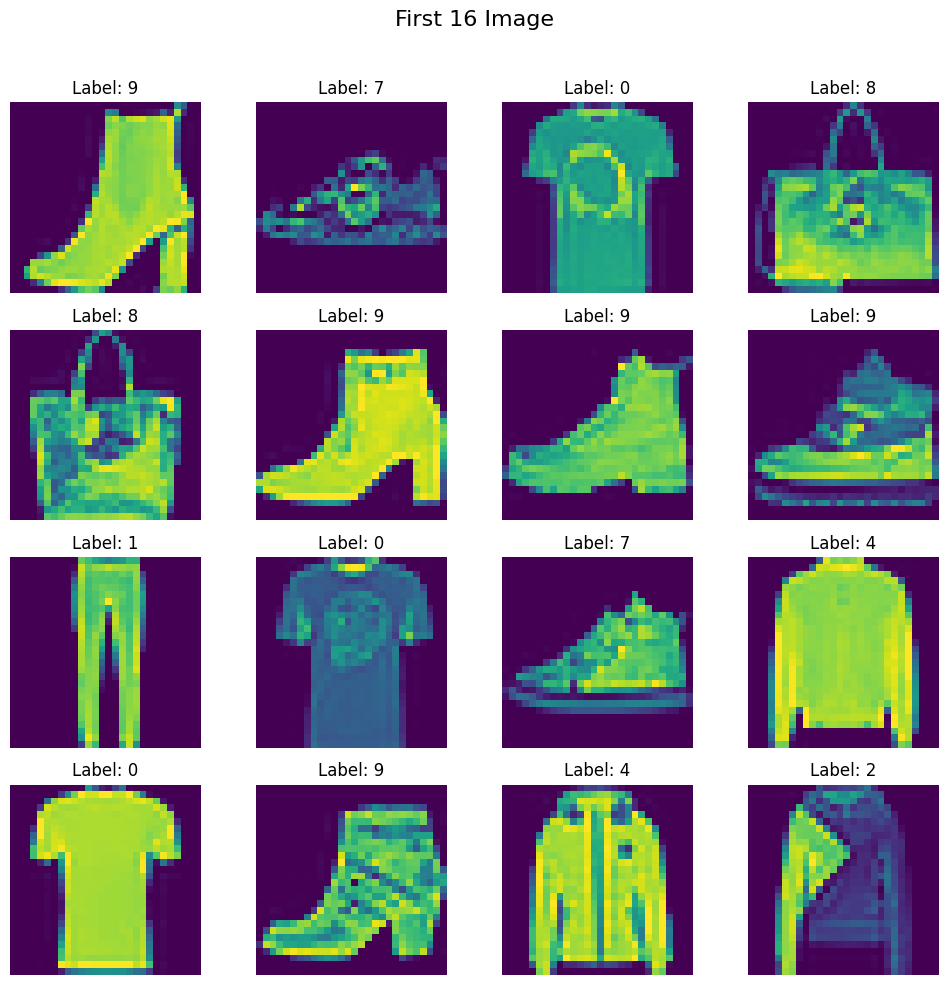

In [11]:
fig, axes = plt.subplots(4,4, figsize=(10,10))
fig.suptitle("First 16 Image", fontsize=16)

#plot the first 16 image from the dataset
for i, ax in enumerate(axes.flat):
  img = df.iloc[i, 1:].values.reshape(28,28) #Reshape to 28x28
  ax.imshow(img) # Display without explicit grayscale colormap
  ax.axis('off') #Remove axis for cleaner look
  ax.set_title(f"Label: {df.iloc[i,0]}") #Show the lable

plt.tight_layout(rect= [0,0,1,0.96]) #Adjust layout to the fit title
plt.show()

In [12]:
#train test split

X = df.iloc[:, 1:].values
y = df.iloc[:, 0].values

In [13]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size= 0.2, random_state=42)

In [14]:
X_train = X_train / 255.0
X_test = X_test /255.0

In [16]:
class CustomDataset(Dataset):
  def __init__(self, features, labels):

    # convert to pytorch tensor
    self.features = torch.tensor(features, dtype = torch.float32)
    self.labels = torch.tensor(labels, dtype = torch.long)

  def __len__(self):
    return len(self.features)

  def __getitem__(self, index):
    return self.features[index],self.labels[index]

In [17]:
train_dataset = CustomDataset(X_train, y_train)
test_dataset = CustomDataset(X_test, y_test)

In [18]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True,pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False,pin_memory=True)

In [19]:
len(train_loader)

119

In [21]:
class MyNN(nn.Module):
  def __init__(self, num_features):
    super().__init__()
    self.model = nn.Sequential(
        nn.Linear(num_features, 128),
        nn.ReLU(),
        nn.Linear(128, 64),
        nn.Linear(64, 10)
    )
  def forward(self, x):
    return self.model(x)


In [22]:
learning_rate = 0.1
epochs = 100

In [27]:
# instatiate the model
model = MyNN(X_train.shape[1])

model = model.to(device)

# loss function
criterion = nn.CrossEntropyLoss()
# optimizer
optimizer = optim.SGD(model.parameters(), lr=learning_rate)

In [28]:
# training loop

for epoch in range(epochs):

  total_epoch_loss = 0

  for batch_features, batch_labels in train_loader:

    # move data to gpu
    batch_features, batch_labels = batch_features.to(device), batch_labels.to(device)

    # forward pass
    outputs = model(batch_features)

    # calculate loss
    loss = criterion(outputs, batch_labels)

    # back pass
    optimizer.zero_grad()
    loss.backward()

    # update grads
    optimizer.step()

    total_epoch_loss = total_epoch_loss + loss.item()

  avg_loss = total_epoch_loss/len(train_loader)
  print(f'Epoch: {epoch + 1} , Loss: {avg_loss}')


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch: 1 , Loss: 1.2959880924024503
Epoch: 2 , Loss: 0.8139986022680747
Epoch: 3 , Loss: 0.6692729458983737
Epoch: 4 , Loss: 0.5945610610627327
Epoch: 5 , Loss: 0.5599618814572567
Epoch: 6 , Loss: 0.5570458993941796
Epoch: 7 , Loss: 0.49559906832560774
Epoch: 8 , Loss: 0.47086144117990647
Epoch: 9 , Loss: 0.4439755914842381
Epoch: 10 , Loss: 0.4274073281333226
Epoch: 11 , Loss: 0.40562579974907786
Epoch: 12 , Loss: 0.3935131729901338
Epoch: 13 , Loss: 0.4549076519593471
Epoch: 14 , Loss: 0.40445579294929235
Epoch: 15 , Loss: 0.3477801003125535
Epoch: 16 , Loss: 0.3352566614371388
Epoch: 17 , Loss: 0.3950915176327489
Epoch: 18 , Loss: 0.326405242774166
Epoch: 19 , Loss: 0.32124081337795113
Epoch: 20 , Loss: 0.28461180636737526
Epoch: 21 , Loss: 0.2758609884802033
Epoch: 22 , Loss: 0.2724094561481175
Epoch: 23 , Loss: 0.2611711100369942
Epoch: 24 , Loss: 0.2536494168413787
Epoch: 25 , Loss: 0.3027403416315548
Epoch: 26 , Loss: 0.36681532247790266
Epoch: 27 , Loss: 0.2962757221290043
Epoc

In [29]:
model.eval()

MyNN(
  (model): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): Linear(in_features=64, out_features=10, bias=True)
  )
)

In [30]:
# evaluation code
total = 0
correct = 0

with torch.no_grad():

  for batch_features, batch_labels in test_loader:

    # move data to gpu
    batch_features, batch_labels = batch_features.to(device), batch_labels.to(device)

    outputs = model(batch_features)

    _, predicted = torch.max(outputs, 1)

    total = total + batch_labels.shape[0]

    correct = correct + (predicted == batch_labels).sum().item()

print(correct/total)

0.7026455026455026


In [31]:
# evaluation code
total = 0
correct = 0

with torch.no_grad():

  for batch_features, batch_labels in train_loader:

    # move data to gpu
    batch_features, batch_labels = batch_features.to(device), batch_labels.to(device)

    outputs = model(batch_features)

    _, predicted = torch.max(outputs, 1)

    total = total + batch_labels.shape[0]

    correct = correct + (predicted == batch_labels).sum().item()

print(correct/total)

0.7572789835892006
